# Notebook 04: Claude Labels and Complaint Trends

**Team:** Teenna Pachika and Johanna Garcia

In this notebook we use Claude to label all the negative reviews, not just a small sample like in Phase 2. Then we check if Claude's labels make sense compared to our keyword rules, and look at which complaints went up or down over time and which ones other users agreed with the most. We save every chart in the `figures/` folder so we can use them in our slides.

In [1]:
# Importing libraries and our shared code from the src folder
import sys
sys.path.append("..")

import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.preprocessing import load_reviews, get_negative
from src.app_versions import get_release_dates

# Loading the data and keeping only the negative reviews
df = load_reviews()
neg = get_negative(df).reset_index(drop=True)

# Getting the app update dates (same function Johanna uses, so our charts match)
release_dates = get_release_dates(df)

# Using the same red as the other notebooks
NEG_COLOR = "#B5544C"

# Making sure the figures folder exists so we can save charts for the slides
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Defining a function to save and show a chart
def save_chart(name):
    """Save the current chart to the figures folder and show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Checking the counts
print(f"All reviews: {len(df):,} | Negative reviews (1-2 stars): {len(neg):,}")
print("App updates found:", len(release_dates))

All reviews: 50,000 | Negative reviews (1-2 stars): 4,147
App updates found: 5


## 1. Labeling All the Negative Reviews with Claude

In Phase 2 we only tested Claude on 8 reviews. Our professor suggested labeling all of them since it's cheap, so that's what we're doing here. We're using the same prompt as our Phase 2 test (version 2), which already lets a review have more than one complaint and has an "other" category.

In [2]:
# Importing tools for the Claude API
import anthropic
from dotenv import load_dotenv

# Loading the API key from the .env file in the main project folder
load_dotenv("../.env", override=True)
client = anthropic.Anthropic(api_key=os.getenv("ANTHROPIC_API_KEY"))

# Using the same small, cheap model as Phase 2
CLAUDE_MODEL = "claude-haiku-4-5"

# Our prompt from Phase 2 (version 2)
PROMPT = """You are labeling negative Duolingo app reviews.
Categories:
- energy_hearts: running out of energy or hearts, limits on how much you can practice
- streak: losing or protecting a streak
- ads: too many ads or ads interrupting lessons
- paywall: having to pay, Super/Max/premium, subscription, price, features locked behind payment
- ai: AI features or Duolingo using AI instead of people
- icon_notifications: the changing app icon or pushy notifications
- bugs: crashes, glitches, things not working
- language_access: missing languages, or users in some countries (like Iran) losing access to features
- teaching_quality: lessons that are wrong, confusing, or don't actually teach well
- other: none of the above

A review can have more than one category. Use "other" only if nothing else fits.
Return ONLY a JSON list, with no other text, like: [{{"id": 0, "labels": ["streak"]}}]

Reviews:
{reviews}"""

# Keeping track of tokens so we can report the cost
tokens = {"in": 0, "out": 0}

# Defining a function to send a batch of reviews to Claude in one call
def label_with_claude(texts, prompt=PROMPT, model=CLAUDE_MODEL):
    """Send numbered reviews to Claude in one call and return a list of labels for each review."""
    numbered = "\n".join(f"{i}: {t}" for i, t in enumerate(texts))
    response = client.messages.create(
        model=model, max_tokens=2000,
        messages=[{"role": "user", "content": prompt.format(reviews=numbered)}],
    )
    raw = response.content[0].text.strip()
    raw = raw.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    tokens["in"] += response.usage.input_tokens
    tokens["out"] += response.usage.output_tokens
    labels = {item["id"]: item["labels"] for item in json.loads(raw)}
    return [labels.get(i, ["missing"]) for i in range(len(texts))]

print("Claude is ready")

Claude is ready


In [3]:
# Testing Claude on 100 random negative reviews first (5 batches of 20), to check the labels and the cost
BATCH_SIZE = 20
test = neg.sample(100, random_state=42).copy()

test_labels = []
for start in range(0, len(test), BATCH_SIZE):
    batch = test["content"].iloc[start:start + BATCH_SIZE].tolist()
    test_labels += label_with_claude(batch)

test["claude_labels"] = test_labels

# Estimating the cost (Haiku 4.5 is about $1 per million input tokens and $5 per million output tokens)
cost = tokens["in"] / 1_000_000 * 1 + tokens["out"] / 1_000_000 * 5
print(f"Tokens used: {tokens['in']:,} in, {tokens['out']:,} out | Cost so far: ${cost:.3f}")
print(f"Estimated cost for all {len(neg):,} reviews: ${cost * len(neg) / len(test):.2f}")
print("Reviews Claude skipped:", sum(labels == ["missing"] for labels in test["claude_labels"]))

# Showing the first 10 so we can read them
test[["content", "claude_labels"]].head(10)

Tokens used: 6,005 in, 1,802 out | Cost so far: $0.015
Estimated cost for all 4,147 reviews: $0.62
Reviews Claude skipped: 0


,content,claude_labels
149,I boycott this app until you activate Duolingo...,[language_access]
1971,ai slop,[ai]
238,"Shame on you, not supporting Persian language ...",[language_access]
3956,its was very fun but i told him i was a begine...,[teaching_quality]
308,it's not completely free 🥺,[paywall]
1255,I didn't know why my mother's gcash acc got in...,[paywall]
4070,These bastards deducted Rs5000 from my account...,[paywall]
1261,good,[other]
70,Whilst the content itself is fine if you buy a...,"[paywall, bugs]"
2053,The energy system really ruined the app for me...,[energy_hearts]


In [4]:
# Labeling all the negative reviews, or loading the saved labels if we already did it
# (this way the notebook can be re-run without paying for Claude again)
LABELS_FILE = "../data/claude_labels.csv"
RELABEL = False   # set to True only if we want to run Claude again (about $0.60)

if RELABEL or not os.path.exists(LABELS_FILE):
    all_labels = []
    for start in range(0, len(neg), BATCH_SIZE):
        batch = neg["content"].iloc[start:start + BATCH_SIZE].tolist()
        try:
            all_labels += label_with_claude(batch)
        except Exception as e:
            print(f"Batch starting at {start} failed: {e}")
            all_labels += [["missing"]] * len(batch)
        if start % 500 == 0:
            print(f"Done {start + len(batch):,} of {len(neg):,}")

    # Saving the labels so we never have to run Claude again
    labels_df = pd.DataFrame({"reviewId": neg["reviewId"], "claude_labels": [json.dumps(l) for l in all_labels]})
    labels_df.to_csv(LABELS_FILE, index=False)
    cost = tokens["in"] / 1_000_000 * 1 + tokens["out"] / 1_000_000 * 5
    print(f"Saved! Total tokens (including the test): {tokens['in']:,} in, {tokens['out']:,} out | Total cost: ${cost:.2f}")
else:
    print("Loading saved labels from", LABELS_FILE)

# Adding the labels to our negative reviews
labels_df = pd.read_csv(LABELS_FILE)
labels_df["claude_labels"] = labels_df["claude_labels"].apply(json.loads)
neg = neg.merge(labels_df, on="reviewId")
print("Reviews with labels:", len(neg))
print("Reviews Claude skipped:", sum(labels == ["missing"] for labels in neg["claude_labels"]))

Done 20 of 4,147
Done 520 of 4,147
Done 1,020 of 4,147
Done 1,520 of 4,147
Done 2,020 of 4,147
Done 2,520 of 4,147
Done 3,020 of 4,147
Done 3,520 of 4,147
Done 4,020 of 4,147
Saved! Total tokens (including the test): 223,696 in, 74,803 out | Total cost: $0.60
Reviews with labels: 4147
Reviews Claude skipped: 0


## 2. Claude vs. Our Keyword Rules

To check if Claude's labels make sense, we compare them with the keyword rules we made in Phase 2. In Phase 2, about 62% of negative reviews didn't match any keyword, so we want to see if Claude can put those reviews into a category.

In [5]:
# Using the same keyword rules as Notebook 01
CATEGORIES = {
    "energy_hearts": r"\benergy\b|\bhearts?\b|\blives\b",
    "streak": r"\bstreaks?\b",
    "ads": r"\bads?\b|\badverts?\b|\badvertisements?\b",
    "paywall": r"\bpremium\b|\bsuper\b|\bmax\b|\bsubscriptions?\b|\bpaid\b|\bpay\b|\bpaying\b|\bmoney\b",
    "ai": r"\bai\b",
    "icon_notifications": r"\bicons?\b|\bnotifications?\b",
    "bugs": r"\bbugs?\b|\bcrash|\bglitch|\bfreez|not working",
}

# Adding a True/False column for each category, once for keywords and once for Claude
for name, pattern in CATEGORIES.items():
    neg[f"kw_{name}"] = neg["content"].str.contains(pattern, case=False, regex=True)
    neg[f"claude_{name}"] = neg["claude_labels"].apply(lambda labels: name in labels)

# Comparing how many reviews each method put in each category
rows = []
for name in CATEGORIES:
    kw = neg[f"kw_{name}"]
    cl = neg[f"claude_{name}"]
    rows.append({
        "category": name,
        "keywords (%)": kw.mean() * 100,
        "Claude (%)": cl.mean() * 100,
        "Claude found, keywords missed": (cl & ~kw).sum(),
        "keywords found, Claude didn't": (kw & ~cl).sum(),
    })
compare = pd.DataFrame(rows).set_index("category").round(1).sort_values("Claude (%)", ascending=False)

# Checking how many reviews each method couldn't place
kw_none = (~neg[[f"kw_{n}" for n in CATEGORIES]].any(axis=1)).mean() * 100
claude_other = neg["claude_labels"].apply(lambda labels: labels == ["other"]).mean() * 100
print(f"Reviews with no keyword category: {kw_none:.1f}%")
print(f"Reviews Claude labeled only 'other': {claude_other:.1f}%")

compare

Reviews with no keyword category: 61.8%
Reviews Claude labeled only 'other': 27.5%


,keywords (%),Claude (%),"Claude found, keywords missed","keywords found, Claude didn't"
category,,,,
bugs,4.7,18.6,597,20
paywall,14.4,16.9,192,92
energy_hearts,8.6,11.1,126,22
ads,9.4,10.8,92,32
icon_notifications,4.8,7.5,120,11
ai,6.5,6.7,16,6
streak,5.6,5.1,25,46


In [6]:
# Reading a few reviews where Claude and the keywords disagree, to see who's right
checks = [
    ("bugs", "Claude found, keywords missed", neg["claude_bugs"] & ~neg["kw_bugs"]),
    ("icon_notifications", "Claude found, keywords missed", neg["claude_icon_notifications"] & ~neg["kw_icon_notifications"]),
    ("streak", "keywords found, Claude didn't", neg["kw_streak"] & ~neg["claude_streak"]),
]

for name, kind, mask in checks:
    print(f"--- {name}: {kind} ---")
    for review in neg[mask]["content"].sample(5, random_state=1):
        print("-", review[:200])
    print()

--- bugs: Claude found, keywords missed ---
- i really hate the chest mode here like i accidentally back my Duolingo and i lost almost 50 elo like wth i need to matches for that
- The buttons along the bottom of the screen stop responding after a while of using the app, also the app icon always changing is annoying because it moves to the end of my homescreen constantly
- won't let me cancel subscription and keep charging my card but saying I don't have a subscription.
- when I it it was great at first until I started getting more further started being more buggy and so picky even when I picked the right answers it works it wrong definitely one star do not recommend
- this app dosent properly like expertly knows chess in some moments if you realize bc even as beginner i know more then this guy i feel and he said my [mistake] was not put over the piece that can be g

--- icon_notifications: Claude found, keywords missed ---
- Owl tastes pretty bad,tastes awful but it looks rotten and it

### Checking the "bugs" label

When we read reviews where Claude and the keywords disagreed, Claude was mostly right, but it was too loose with "bugs." For example, it labeled a review about losing chess Elo by accident as a bug, which is really about the game rules. Since bugs came out as the biggest complaint (18.6%), we wanted to make sure that number is real. So we asked Claude to double-check only the reviews it labeled as bugs, using a stricter definition.

In [7]:
# A stricter prompt to double-check only the reviews Claude labeled as "bugs"
BUGS_PROMPT = """Each review below was labeled as a "bug" complaint about the Duolingo app.
Decide if the review really describes a technical problem: crashes, freezing, buttons or features not responding, error messages, lost progress or data because of a glitch, or being charged when the app says there's no subscription.
Complaints about how a feature is designed, game rules (like chess Elo), lesson content, or teaching quality are NOT bugs.
Return ONLY a JSON list, with no other text, like: [{{"id": 0, "bug": true}}]

Reviews:
{reviews}"""

BUGS_FILE = "../data/claude_bugs_check.csv"

# Defining a function to ask Claude if each review is really a bug
def check_bugs(texts):
    """Send numbered reviews to Claude and return True/False for whether each one is really a bug."""
    numbered = "\n".join(f"{i}: {t}" for i, t in enumerate(texts))
    response = client.messages.create(
        model=CLAUDE_MODEL, max_tokens=1000,
        messages=[{"role": "user", "content": BUGS_PROMPT.format(reviews=numbered)}],
    )
    raw = response.content[0].text.strip()
    raw = raw.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    tokens["in"] += response.usage.input_tokens
    tokens["out"] += response.usage.output_tokens
    answers = {item["id"]: item["bug"] for item in json.loads(raw)}
    return [answers.get(i, True) for i in range(len(texts))]

# Re-checking the bugs reviews, or loading the saved results (same idea as before, so we only pay once)
bug_reviews = neg[neg["claude_bugs"]]
if RELABEL or not os.path.exists(BUGS_FILE):
    tokens_before = dict(tokens)
    really_bug = []
    for start in range(0, len(bug_reviews), BATCH_SIZE):
        batch = bug_reviews["content"].iloc[start:start + BATCH_SIZE].tolist()
        really_bug += check_bugs(batch)
    pd.DataFrame({"reviewId": bug_reviews["reviewId"], "really_bug": really_bug}).to_csv(BUGS_FILE, index=False)
    extra_in = tokens["in"] - tokens_before["in"]
    extra_out = tokens["out"] - tokens_before["out"]
    print(f"Re-check tokens: {extra_in:,} in, {extra_out:,} out | Cost: ${extra_in / 1_000_000 * 1 + extra_out / 1_000_000 * 5:.2f}")

# Removing the "bugs" label from reviews that aren't really bugs
bugs_check = pd.read_csv(BUGS_FILE)
not_bugs = set(bugs_check.loc[~bugs_check["really_bug"], "reviewId"])

def remove_bug(row):
    """Take "bugs" off a review's labels if the re-check said it isn't a bug."""
    labels = row["claude_labels"]
    if row["reviewId"] in not_bugs:
        labels = [label for label in labels if label != "bugs"] or ["other"]
    return labels

neg["claude_labels"] = neg.apply(remove_bug, axis=1)
neg["claude_bugs"] = neg["claude_labels"].apply(lambda labels: "bugs" in labels)

print(f"Reviews labeled bugs: {len(bug_reviews)} before the re-check, {neg['claude_bugs'].sum()} after")
print(f"Bugs is now {neg['claude_bugs'].mean() * 100:.1f}% of negative reviews (keywords: {neg['kw_bugs'].mean() * 100:.1f}%)")

# Showing a few reviews that were taken out of bugs
print("\nExamples that are NOT bugs after the re-check:")
for review in bug_reviews[bug_reviews["reviewId"].isin(not_bugs)]["content"].head(5):
    print("-", review[:200])

Re-check tokens: 47,784 in, 10,465 out | Cost: $0.10
Reviews labeled bugs: 772 before the re-check, 563 after
Bugs is now 13.6% of negative reviews (keywords: 4.7%)

Examples that are NOT bugs after the re-check:
- Never been the same after the big update.
- hi the voice translator of duo is quite please fix it
- раньше было хорошее приложение, сейчас много глюков и прикол с энергией, которая быстро заканчивается, просто отбивает желание заходить и заниматься
- Changes get made so often. A whole unit I'd completed was changed from talking about family or being about dining out with friends. A whole unit full of words I'd never learned but because of the chan
- The sound lesson are terrible, I got so many falses just because the app doesn't really good at listening the user. It get me everytime.


No category: keywords 61.8% vs Claude 30.4%


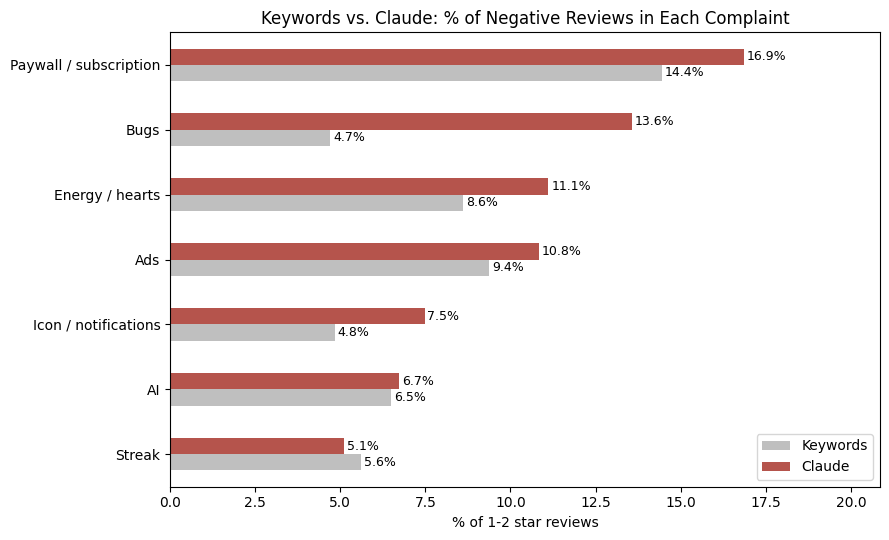

In [8]:
# Nicer names for the charts
NICE_NAMES = {
    "energy_hearts": "Energy / hearts", "streak": "Streak", "ads": "Ads", "paywall": "Paywall / subscription",
    "ai": "AI", "icon_notifications": "Icon / notifications", "bugs": "Bugs",
    "language_access": "Language access", "teaching_quality": "Teaching quality",
}

# Recalculating the % for each category, using the checked labels
compare_chart = pd.DataFrame({
    "Keywords": [neg[f"kw_{n}"].mean() * 100 for n in CATEGORIES],
    "Claude": [neg[f"claude_{n}"].mean() * 100 for n in CATEGORIES],
}, index=[NICE_NAMES[n] for n in CATEGORIES]).sort_values("Claude")

# How many reviews each method couldn't place
claude_other = neg["claude_labels"].apply(lambda labels: labels == ["other"]).mean() * 100
print(f"No category: keywords {kw_none:.1f}% vs Claude {claude_other:.1f}%")

# Plotting keywords vs Claude side by side
ax = compare_chart.plot(kind="barh", color=["#BFBFBF", NEG_COLOR], figsize=(9, 5.5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=9)
plt.title("Keywords vs. Claude: % of Negative Reviews in Each Complaint")
plt.xlabel("% of 1-2 star reviews")
plt.ylabel("")
plt.xlim(0, compare_chart.max().max() + 4)
plt.legend(loc="lower right")
save_chart("09_claude_vs_keywords")

### What we found

Claude was able to put a lot more reviews into a category than our keyword rules. With keywords, 61.8% of negative reviews didn't match anything, but with Claude only 30.4% ended up as "other." Most of the leftover ones are really short or vague, like "so bad" or "good."

The biggest difference was bugs. Keywords only found 4.7%, but Claude found 13.6% (even after we re-checked it), so I think people just describe bugs in a lot of different ways, like "buttons stop responding" or "marks my right answer wrong," instead of saying "bug" or "crash." Icon and notification complaints also went up (4.8% to 7.5%) because people say things like "stop changing the faces of the app" without ever saying "icon."

Streak was the only one where keywords found more than Claude. When we read those reviews, a lot of them just mentioned a streak ("I hit a 4000 day streak") without actually complaining about it, so Claude was right not to count them.

Claude wasn't perfect though. The re-check took out a Russian review that literally says "lots of glitches," so it's possible Claude is a little worse with non-English reviews. Labeling everything cost about $0.70 total ($0.60 for the labels and $0.10 for the bugs re-check).

## 3. Do Complaints Change After App Updates?

Our professor noticed that negative reviews went from about 7.5% to almost 10% of all reviews in late August. Here we check which complaints made that jump happen. We count each complaint per 100 reviews (out of all reviews that week), so we can see which ones actually grew. The dashed lines are app updates, using Johanna's `get_release_dates` function so our charts match.

Complaints per 100 reviews, by week:
            Paywall / subscription  Bugs  Energy / hearts   Ads  \
at                                                                
2026-08-02                    1.40  1.19             0.87  0.92   
2026-08-09                    1.24  1.28             0.89  0.73   
2026-08-16                    1.40  1.06             0.93  0.93   
2026-08-23                    1.56  1.10             1.05  1.11   
2026-08-30                    1.64  1.06             0.96  0.88   
2026-09-06                    1.19  1.08             0.83  0.85   

            Icon / notifications  Language access  
at                                                 
2026-08-02                  0.37             0.44  
2026-08-09                  0.33             0.38  
2026-08-16                  0.25             0.45  
2026-08-23                  0.48             0.33  
2026-08-30                  0.97             1.42  
2026-09-06                  1.17             1.16  

Before vs

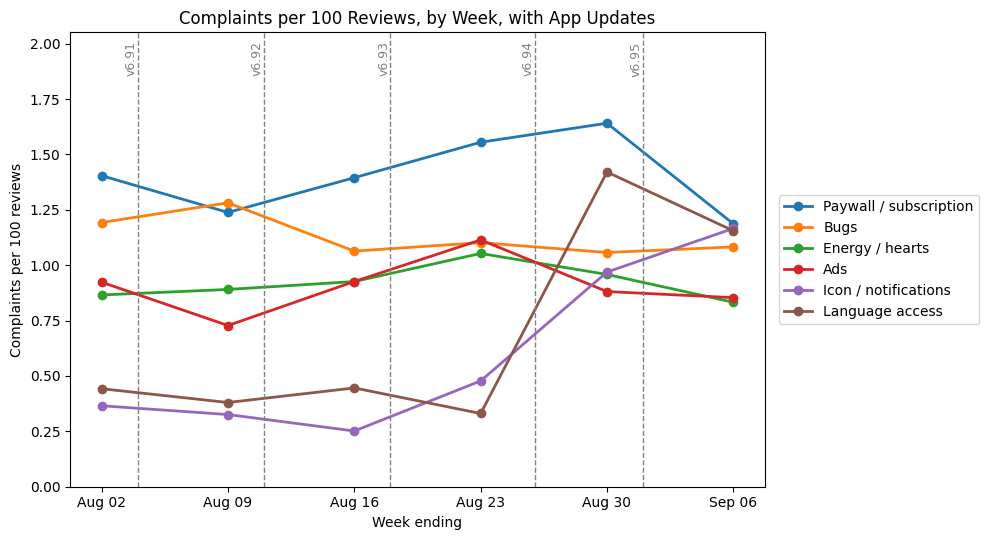

In [12]:
import matplotlib.dates as mdates

# Adding True/False columns for the two categories only Claude has
for name in ["language_access", "teaching_quality"]:
    neg[f"claude_{name}"] = neg["claude_labels"].apply(lambda labels: name in labels)

# Only using reviews up to Sep 6 (there's just one review after that, same as Notebook 03)
recent = df[df["at"] < "2026-09-07"]
recent_neg = neg[neg["at"] < "2026-09-07"]

# Counting each complaint per week, out of ALL reviews that week (per 100 reviews)
MAIN = ["paywall", "bugs", "energy_hearts", "ads", "icon_notifications", "language_access"]
weekly_total = recent.set_index("at").resample("W").size()
weekly_counts = recent_neg.set_index("at")[[f"claude_{n}" for n in MAIN]].resample("W").sum()
weekly = weekly_counts.div(weekly_total, axis=0) * 100
weekly.columns = [NICE_NAMES[n] for n in MAIN]
print("Complaints per 100 reviews, by week:")
print(weekly.round(2))

# Comparing before the jump (weeks ending Aug 2-23) with after (Aug 30-Sep 6)
change = pd.DataFrame({
    "before (per 100)": weekly.loc[:"2026-08-23"].mean(),
    "after (per 100)": weekly.loc["2026-08-30":].mean(),
})
change["change"] = change["after (per 100)"] - change["before (per 100)"]
print("\nBefore vs after the late-August jump:")
print(change.round(2).sort_values("change", ascending=False))

# Plotting each complaint over time, with dashed lines for app updates
fig, ax = plt.subplots(figsize=(10, 5.5))
for name in weekly.columns:
    ax.plot(weekly.index, weekly[name], marker="o", linewidth=2, label=name)

top = weekly.max().max() * 1.25
ax.set_ylim(0, top)
for version, date in release_dates.items():
    ax.axvline(date, color="gray", linestyle="--", linewidth=1)
    ax.text(date, top * 0.98, f"v{version}", rotation=90, va="top", ha="right", fontsize=9, color="gray")

ax.set_xticks(weekly.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.title("Complaints per 100 Reviews, by Week, with App Updates")
plt.xlabel("Week ending")
plt.ylabel("Complaints per 100 reviews")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
save_chart("10_complaints_over_time")

In [14]:
# Checking every category (plus "other") so we know what explains the whole jump
neg["claude_other"] = neg["claude_labels"].apply(lambda labels: labels == ["other"])
recent_neg = neg[neg["at"] < "2026-09-07"]

ALL = list(NICE_NAMES) + ["other"]
all_counts = recent_neg.set_index("at")[[f"claude_{n}" for n in ALL]].resample("W").sum()
all_weekly = all_counts.div(weekly_total, axis=0) * 100
all_weekly.columns = [NICE_NAMES.get(n, "Other") for n in ALL]

all_change = pd.DataFrame({
    "before (per 100)": all_weekly.loc[:"2026-08-23"].mean(),
    "after (per 100)": all_weekly.loc["2026-08-30":].mean(),
})
all_change["change"] = all_change["after (per 100)"] - all_change["before (per 100)"]
print(all_change.round(2).sort_values("change", ascending=False))

# Overall negative reviews per 100, before vs after
neg_per_100 = recent_neg.set_index("at").resample("W").size() / weekly_total * 100
print(f"\nAll negative reviews per 100: before {neg_per_100.loc[:'2026-08-23'].mean():.2f}, after {neg_per_100.loc['2026-08-30':].mean():.2f}")

                        before (per 100)  after (per 100)  change
Language access                     0.40             1.29    0.89
Icon / notifications                0.36             1.07    0.71
Other                               2.35             2.77    0.42
Teaching quality                    1.42             1.58    0.16
AI                                  0.51             0.65    0.14
Streak                              0.38             0.49    0.10
Paywall / subscription              1.40             1.41    0.02
Energy / hearts                     0.93             0.90   -0.04
Ads                                 0.92             0.87   -0.06
Bugs                                1.16             1.07   -0.09

All negative reviews per 100: before 7.58, after 9.50
